# Quantum carpets: the Talbot effect in a box

A wavepacket in an infinite square well of width $L$ has energies $E_n = n^2 E_1$ with
$E_1 = \pi^2/2L^2$. Since all $n^2$ are integers, every phase $e^{-iE_nt}$ returns to 1 at the
*revival time*

$$T_\mathrm{rev} = \frac{2\pi}{E_1} = \frac{4L^2}{\pi},$$

and the initial state reappears exactly. At rational fractions $t = (p/q)\,T_\mathrm{rev}$ the packet
is rebuilt as a few copies of itself (*fractional revivals*). Plotted in the $(x, t)$ plane, $|\psi|^2$
forms an intricate "quantum carpet", the quantum analogue of the optical Talbot effect
(Berry, Marzoli and Schleich, Physics World **14**(6), 39 (2001)).

In [ ]:
# On Colab (or anywhere without the package), install it from GitHub first:
try:
    import so_schroedinger  # noqa: F401
except ImportError:
    %pip install -q git+https://github.com/aeberspaecher/splitoperator

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 72

## Hard walls by the method of images

A finite grid potential cannot be infinitely high. Instead we use the periodic grid itself: on a ring
of circumference $2L$, an *odd* state $\psi(-x) = -\psi(x)$ stays odd and therefore vanishes at
$x = 0$ and $x = L$ at all times. On $[0, L]$ it evolves exactly like a state in the infinite well.
We start with a Gaussian at $x_0 = 0.3\,L$ minus its mirror image at $-x_0$. Without a potential, a
split operator step is exact for any time step, so the carpet is free of time step errors.

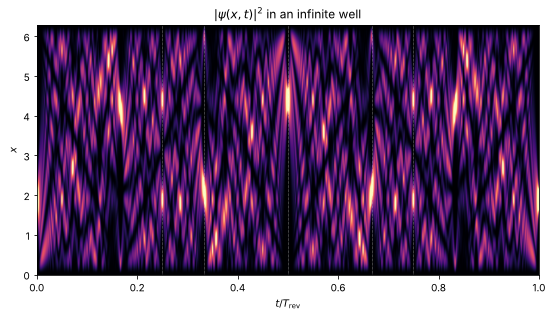

In [2]:
L = 2 * np.pi
T_rev = 4 * L**2 / np.pi
x0, sigma = 0.3 * L, 0.25

grid = so.Grid1d((-L, L), 2**10, so.ConstantPotential(0.0), so.Gaussian1d(x0, sigma, 0.0))
x = grid.x_vals
grid.psi = so.Gaussian1d(x0, sigma, 0.0).psi(x) - so.Gaussian1d(-x0, sigma, 0.0).psi(x)
grid.renormalize_psi()

n_steps = 2000
frames = []
corr = so.analyzers.AutoCorrelation()
corr(grid)
frames.append(grid.density)
so.SplitOperator().propagate(grid, T_rev / n_steps, n_steps, callback=[corr, lambda g: frames.append(g.density)])
carpet = np.array(frames)[:, x >= 0]  # the physical half, 0 <= x < L

plt.figure(figsize=(9, 4.5))
plt.imshow(carpet.T, origin="lower", aspect="auto", extent=(0, 1, 0, L), cmap="magma", vmax=np.percentile(carpet, 99.5))
for f in (1 / 4, 1 / 3, 1 / 2, 2 / 3, 3 / 4):
    plt.axvline(f, c="w", lw=0.5, ls=":")
plt.xlabel(r"$t/T_\mathrm{rev}$")
plt.ylabel("$x$")
plt.title(r"$|\psi(x, t)|^2$ in an infinite well");

## Fractional revivals

At $t = T_\mathrm{rev}/2$ the packet reappears mirrored at $L - x_0$, at $T_\mathrm{rev}/4$ as two
copies and at $T_\mathrm{rev}/3$ as three copies, two of which overlap here. The autocorrelation $|C(t)| = |\langle\psi_0|\psi(t)\rangle|$ returns to 1
at $T_\mathrm{rev}$ and shows the partial revivals in between.

|C(T_rev)| = 1.0000000000001696


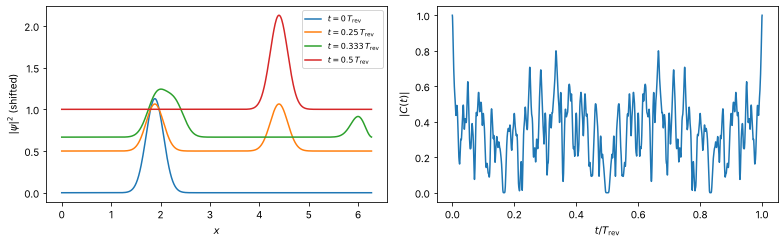

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
xs = x[x >= 0]
for f in (0, 1 / 4, 1 / 3, 1 / 2):
    ax1.plot(xs, carpet[round(f * n_steps)] + 2 * f, label=f"$t = {f:.3g}\\,T_\\mathrm{{rev}}$")
ax1.set(xlabel="$x$", ylabel=r"$|\psi|^2$ (shifted)")
ax1.legend(fontsize=8)
ax2.plot(corr.t / T_rev, np.abs(corr.C))
ax2.set(xlabel=r"$t/T_\mathrm{rev}$", ylabel=r"$|C(t)|$")
plt.tight_layout()
print("|C(T_rev)| =", np.abs(corr.C[-1]))

## Finite walls spoil the revival

With a finite box, $V = V_0$ outside $[0, L]$, the wavefunction leaks into the walls by about
$1/\sqrt{2V_0}$ on each side. The well looks wider, $L_\mathrm{eff} \approx L + 2/\sqrt{2V_0}$, and
higher states, which leak more, no longer have energies exactly proportional to $n^2$. The revival
comes later and is incomplete.

revival at t = 1.0186 T_rev with |C| = 0.891


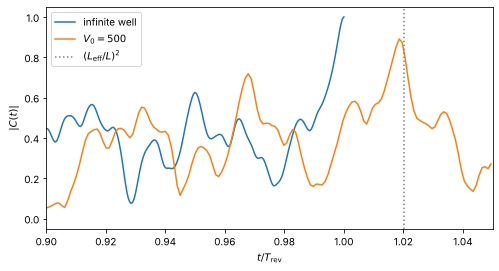

In [4]:
V0, dt = 500.0, 1e-3
box = so.ConstantPotential(V0) + so.BoxPotential(L / 2, L / 2, -V0)
grid_box = so.Grid1d((-0.5, L + 0.5), 2**10, box, so.Gaussian1d(x0, sigma, 0.0))
corr_box = so.analyzers.AutoCorrelation()
corr_box(grid_box)
so.SplitOperator().propagate(grid_box, dt, round(1.05 * T_rev / dt), callback=corr_box, every=50)

t, C = corr_box.t / T_rev, np.abs(corr_box.C)
late = t > 0.9
L_eff = L + 2 / np.sqrt(2 * V0)
plt.plot(corr.t / T_rev, np.abs(corr.C), label="infinite well")
plt.plot(t, C, label=f"$V_0 = {V0:g}$")
plt.axvline((L_eff / L) ** 2, c="gray", ls=":", label=r"$(L_\mathrm{eff}/L)^2$")
plt.xlim(0.9, 1.05)
plt.xlabel(r"$t/T_\mathrm{rev}$")
plt.ylabel(r"$|C(t)|$")
plt.legend()
print(f"revival at t = {t[late][np.argmax(C[late])]:.4f} T_rev with |C| = {C[late].max():.3f}")